# DATA3001 RQ2 — Optimised FNN sensitivity, cluster bootstrap, and regional retraining

Sections 1–4 analyse the global Optimised FNN. Sections 5–6 compare five model versions on the fixed Kuroshio Core subset of the RQ1 test partition. Tables are written to `RQ2/data/optimised_fnn_analysis` and figures to `~/Desktop/figure`. Run from the project root or a project subfolder.

## 0. Inputs and provenance

Required for sensitivity: `output/rq1/zh/optimised_fnn_test_case_metrics.csv`, `RQ2/data/forecast_case_regimes.csv`, and ideally `RQ2/data/glorys_climatology_1994_2022.nc`. If the grid is absent, the notebook uses the existing case labels from `RQ2/16b_regime_sensitivity.py` and **marks them as precomputed**, so it does not claim a fresh grid recomputation.

Regional refits require `forecast_origins.parquet` and `region_A_observations.parquet`. Global scores come from the version-specific RQ1 case metrics. See section 5 for the fit settings and availability rules.

In [1]:
from pathlib import Path
import copy, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.ndimage import label
from scipy.spatial import cKDTree

# Find the project from the notebook's working directory (including subfolders).
# The Desktop location remains a fallback for the original Mac setup.
def find_project_root():
    for parent in (Path.cwd(), *Path.cwd().parents):
        candidate = parent / "data3001-group-project-main"
        if (candidate / "RQ2/data/forecast_case_regimes.csv").is_file():
            return candidate
        if (parent / "RQ2/data/forecast_case_regimes.csv").is_file():
            return parent
    return Path.home() / "Desktop/data3001/data3001-group-project-main"

ROOT = find_project_root()
BASE = ROOT.parent

DATA = ROOT / "RQ2" / "data"
OUT = DATA / "optimised_fnn_analysis"
FIG = Path.home() / "Desktop" / "figure"

CLIM = DATA / "glorys_climatology_1994_2022.nc"
SAVED_LABELS = DATA / "rq2_sensitivity_case_labels.csv"
REGIMES = DATA / "forecast_case_regimes.csv"



# Accept both the repository layout and the original Desktop data layout.
DESKTOP_PROJECT = Path.home() / "Desktop/data3001/data3001-group-project-main"
def rq1_output(filename):
    relative = Path("output/rq1/zh") / filename
    local = ROOT / relative
    desktop = DESKTOP_PROJECT / relative
    return desktop if not local.is_file() and desktop.is_file() else local

OPT_ERRORS = rq1_output("optimised_fnn_test_case_metrics.csv")
PROCESSED_DIRS = (
    ROOT / "data/processed", BASE / "processed", DESKTOP_PROJECT.parent / "processed"
)
PROCESSED = next(
    (p for p in PROCESSED_DIRS if all(
        (p / name).is_file() for name in ("forecast_origins.parquet", "region_A_observations.parquet")
    )),
    PROCESSED_DIRS[0],
)
ORIGINS = PROCESSED / "forecast_origins.parquet"
OBS = PROCESSED / "region_A_observations.parquet"

N_BOOT = 2000
SEED = 3001
SPEED_THRESHOLDS = (0.4, 0.5, 0.6)
BUFFERS_KM = (25, 50, 75)

OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

inputs = pd.DataFrame({
    "input": [
        str(p) for p in
        [CLIM, SAVED_LABELS, REGIMES, OPT_ERRORS, ORIGINS, OBS]
    ],
    "available": [
        p.is_file() for p in
        [CLIM, SAVED_LABELS, REGIMES, OPT_ERRORS, ORIGINS, OBS]
    ]
})

print("Project root:", ROOT)
print("RQ2 exists:", (ROOT / "RQ2").is_dir())
display(inputs)

if not REGIMES.is_file() or not OPT_ERRORS.is_file() or not (
    CLIM.is_file() or SAVED_LABELS.is_file()
):
    raise FileNotFoundError(
        "Missing required sensitivity analysis inputs."
    )

Project root: /Users/zudemac/Desktop/data3001/data3001-group-project-main
RQ2 exists: True


,input,available
0,/Users/zudemac/Desktop/data3001/data3001-group...,False
1,/Users/zudemac/Desktop/data3001/data3001-group...,True
2,/Users/zudemac/Desktop/data3001/data3001-group...,True
3,/Users/zudemac/Desktop/data3001/data3001-group...,True
4,/Users/zudemac/Desktop/data3001/processed/fore...,True
5,/Users/zudemac/Desktop/data3001/processed/regi...,True


## 1. Load the same 757 test cases

Join by `forecast_case_id`, verify drifter identity and finite nonnegative 72h errors. The old `RQ2/data/rq2_test_model_errors_long.csv` uses an earlier FNN and is deliberately not used here.

In [2]:
reg = pd.read_csv(REGIMES)
opt = pd.read_csv(OPT_ERRORS)
assert reg.forecast_case_id.is_unique and opt.forecast_case_id.is_unique
assert {'forecast_case_id','ID','partition','origin_longitude','origin_latitude','depth_m','regime','glorys_match_valid'} <= set(reg)
assert {'forecast_case_id','drifter_id','error_72h_km'} <= set(opt)
cases = reg.loc[reg.partition.eq('test')].merge(opt[['forecast_case_id','drifter_id','error_72h_km']], on='forecast_case_id',validate='one_to_one',indicator=True).sort_values('forecast_case_id').reset_index(drop=True)
assert len(cases)==len(opt)==757 and cases._merge.eq('both').all()
assert (cases.ID.astype(str)==cases.drifter_id.astype(str)).all()
assert cases.ID.nunique()==71
assert cases.glorys_match_valid.fillna(False).astype(bool).all()
assert np.isfinite(cases[['origin_longitude','origin_latitude','depth_m','error_72h_km']].to_numpy(float)).all()
assert cases.depth_m.ge(0).all() and cases.error_72h_km.ge(0).all()
print('Optimised FNN:',len(cases),'test cases;',cases.ID.nunique(),'drifters')

Optimised FNN: 757 test cases; 71 drifters


## 2. Reclassify physical regimes

GLORYS uses speed $\sqrt{u^2+v^2}$; at each threshold, 8-neighbour components are labelled and the **two largest** are the Core. A case matches the nearest wet grid cell (≤15 km). GEBCO `depth_m` from the existing case table gives Shelf ≤200 m; otherwise Transition if depth ≤1000 m or distance to Core ≤buffer; remaining cases are Other Offshore. Priority: Core → Shelf → Transition → Other Offshore. The 0.5 m/s, 50 km labels must exactly reproduce the saved main classification.


In [3]:
def xyz(lon,lat):
    lon,lat=np.deg2rad(np.asarray(lon,float)),np.deg2rad(np.asarray(lat,float))
    return np.column_stack((np.cos(lat)*np.cos(lon),np.cos(lat)*np.sin(lon),np.sin(lat)))
def chord_km(chord):
    return 2*6371.0088*np.arcsin(np.clip(np.asarray(chord)/2,0,1))
def recompute_labels(cases, path):
    import xarray as xr
    with xr.open_dataset(path) as ds:
        u=ds['u_mean'].squeeze(drop=True).transpose('latitude','longitude').values
        v=ds['v_mean'].squeeze(drop=True).transpose('latitude','longitude').values
        lon,lat=ds.longitude.values,ds.latitude.values
    speed=np.hypot(u,v); wet=np.isfinite(speed)
    lg,ag=np.meshgrid(lon,lat)
    wet_tree=cKDTree(xyz(lg[wet],ag[wet]))
    d,ix=wet_tree.query(xyz(cases.origin_longitude,cases.origin_latitude))
    assert chord_km(d).max()<=15, 'GLORYS match exceeds 15 km'
    rr,cc=np.unravel_index(np.flatnonzero(wet)[ix],wet.shape)
    rows=[]
    for threshold in SPEED_THRESHOLDS:
        components,_=label(wet & (speed>=threshold),structure=np.ones((3,3),int))
        sizes=np.bincount(components.ravel()); sizes[0]=0
        if len(sizes)<3: raise ValueError(f'Fewer than two current components at {threshold}')
        top2=np.argsort(sizes)[-2:][::-1]
        core_grid=np.isin(components,top2)
        core_tree=cKDTree(xyz(lg[core_grid],ag[core_grid]))
        distance=chord_km(core_tree.query(xyz(cases.origin_longitude,cases.origin_latitude))[0])
        is_core=core_grid[rr,cc]
        for buffer in BUFFERS_KM:
            shelf=(~is_core)&(cases.depth_m.to_numpy()<=200)
            transition=(~is_core)&(~shelf)&((cases.depth_m.to_numpy()<=1000)|(distance<=buffer))
            regimes=np.full(len(cases),'Other Offshore',dtype=object)
            regimes[transition]='Transition'; regimes[shelf]='Shelf'; regimes[is_core]='Kuroshio Core'
            rows.append(pd.DataFrame({'forecast_case_id':cases.forecast_case_id,'ID':cases.ID,'speed_threshold_m_s':threshold,'buffer_km':buffer,'regime':regimes,'distance_to_core_km':distance}))
    return pd.concat(rows,ignore_index=True)

if CLIM.is_file():
    labels=recompute_labels(cases,CLIM)
    label_source='fresh GLORYS grid recomputation'
    if SAVED_LABELS.is_file():
        old=pd.read_csv(SAVED_LABELS)
        check=labels.merge(old[['forecast_case_id','speed_threshold_m_s','buffer_km','regime']],on=['forecast_case_id','speed_threshold_m_s','buffer_km'],suffixes=('_new','_saved'),validate='one_to_one')
        print('Saved sensitivity label agreement:',(check.regime_new==check.regime_saved).mean())
else:
    labels=pd.read_csv(SAVED_LABELS)
    label_source='precomputed RQ2/16b_regime_sensitivity.py labels; GLORYS grid unavailable'
required={'forecast_case_id','ID','speed_threshold_m_s','buffer_km','regime'}
assert required<=set(labels)
assert not labels.duplicated(['forecast_case_id','speed_threshold_m_s','buffer_km']).any()
assert len(labels)==len(cases)*9
assert set(labels.forecast_case_id)==set(cases.forecast_case_id)
assert set(zip(labels.speed_threshold_m_s,labels.buffer_km))=={(a,b) for a in SPEED_THRESHOLDS for b in BUFFERS_KM}
main=labels.loc[np.isclose(labels.speed_threshold_m_s,.5)&labels.buffer_km.eq(50)].sort_values('forecast_case_id')
assert np.array_equal(main.regime.to_numpy(),cases.regime.to_numpy()), '0.5 m/s, 50 km fails to reproduce RQ2 main labels'
assert (main.ID.astype(str).to_numpy()==cases.ID.astype(str).to_numpy()).all()
print('Label source:',label_source)
print('Main setting reproduces all',len(main),'labels')

Label source: precomputed RQ2/16b_regime_sensitivity.py labels; GLORYS grid unavailable
Main setting reproduces all 757 labels


## 3. Core−Shelf 72h endpoint errors

For each setting, report median and RMSE of the **same fixed global Optimised FNN** errors in newly assigned Core and Shelf cases. Difference = metric(Core) − metric(Shelf), in km. Bootstrap resamples drifter IDs with replacement, carrying all their cases together; the same sampled IDs are used across settings. CI is percentile 95%.

In [4]:
joined=labels.merge(cases[['forecast_case_id','ID','error_72h_km']],on='forecast_case_id',suffixes=('_label',''),validate='many_to_one')
assert (joined.ID_label.astype(str)==joined.ID.astype(str)).all()
ids=cases.ID.to_numpy(); unique=np.unique(ids)
by_id=[np.flatnonzero(ids==x) for x in unique]
rng=np.random.default_rng(SEED)
draws=rng.integers(0,len(unique),size=(N_BOOT,len(unique)))
boot_indices=[np.concatenate([by_id[j] for j in draw]) for draw in draws]
def rmse(x): return float(np.sqrt(np.mean(np.square(x))))
rows=[]; count_rows=[]
for threshold in SPEED_THRESHOLDS:
 for buffer in BUFFERS_KM:
    setting=joined.loc[np.isclose(joined.speed_threshold_m_s,threshold)&joined.buffer_km.eq(buffer)].sort_values('forecast_case_id')
    assert np.array_equal(setting.forecast_case_id.to_numpy(),cases.forecast_case_id.to_numpy())
    lab=setting.regime.to_numpy(); err=cases.error_72h_km.to_numpy(float)
    core=lab=='Kuroshio Core'; shelf=lab=='Shelf'
    for name in ['Kuroshio Core','Shelf','Transition','Other Offshore']:
        mask=lab==name
        count_rows.append({'threshold_m_s':threshold,'buffer_km':buffer,'regime':name,'n_cases':int(mask.sum()),'n_drifters':int(np.unique(ids[mask]).size)})
    if not core.any() or not shelf.any():
        raise ValueError(f'Empty Core or Shelf at {threshold}, {buffer}')
    reps_med=[]; reps_rmse=[]
    for bi in boot_indices:
        c=err[bi[core[bi]]]; s=err[bi[shelf[bi]]]
        if len(c) and len(s):
            reps_med.append(np.median(c)-np.median(s)); reps_rmse.append(rmse(c)-rmse(s))
    for metric,func,reps in [('median',np.median,reps_med),('rmse',rmse,reps_rmse)]:
        lo,hi=np.percentile(reps,[2.5,97.5]) if reps else (np.nan,np.nan)
        rows.append({'threshold_m_s':threshold,'buffer_km':buffer,'metric':metric,'core_km':float(func(err[core])),'shelf_km':float(func(err[shelf])),'core_minus_shelf_km':float(func(err[core])-func(err[shelf])),'ci_low_km':lo,'ci_high_km':hi,'n_core':int(core.sum()),'n_shelf':int(shelf.sum()),'valid_bootstrap':len(reps),'label_source':label_source})
sensitivity=pd.DataFrame(rows); counts=pd.DataFrame(count_rows)
sensitivity.to_csv(OUT/'sensitivity_optimised_fnn.csv',index=False)
counts.to_csv(OUT/'sensitivity_regime_counts.csv',index=False)
display(sensitivity.round(2))

,threshold_m_s,buffer_km,metric,core_km,shelf_km,core_minus_shelf_km,ci_low_km,ci_high_km,n_core,n_shelf,valid_bootstrap,label_source
0,0.4,25,median,61.22,24.46,36.76,28.59,50.61,177,108,2000,precomputed RQ2/16b_regime_sensitivity.py labe...
1,0.4,25,rmse,87.29,36.84,50.46,40.22,60.83,177,108,2000,precomputed RQ2/16b_regime_sensitivity.py labe...
2,0.4,50,median,61.22,24.46,36.76,28.59,50.61,177,108,2000,precomputed RQ2/16b_regime_sensitivity.py labe...
3,0.4,50,rmse,87.29,36.84,50.46,40.22,60.83,177,108,2000,precomputed RQ2/16b_regime_sensitivity.py labe...
4,0.4,75,median,61.22,24.46,36.76,28.59,50.61,177,108,2000,precomputed RQ2/16b_regime_sensitivity.py labe...
5,0.4,75,rmse,87.29,36.84,50.46,40.22,60.83,177,108,2000,precomputed RQ2/16b_regime_sensitivity.py labe...
6,0.5,25,median,61.22,24.66,36.55,27.57,52.30,139,112,2000,precomputed RQ2/16b_regime_sensitivity.py labe...
7,0.5,25,rmse,85.86,40.83,45.04,31.98,57.33,139,112,2000,precomputed RQ2/16b_regime_sensitivity.py labe...
8,0.5,50,median,61.22,24.66,36.55,27.57,52.30,139,112,2000,precomputed RQ2/16b_regime_sensitivity.py labe...
9,0.5,50,rmse,85.86,40.83,45.04,31.98,57.33,139,112,2000,precomputed RQ2/16b_regime_sensitivity.py labe...


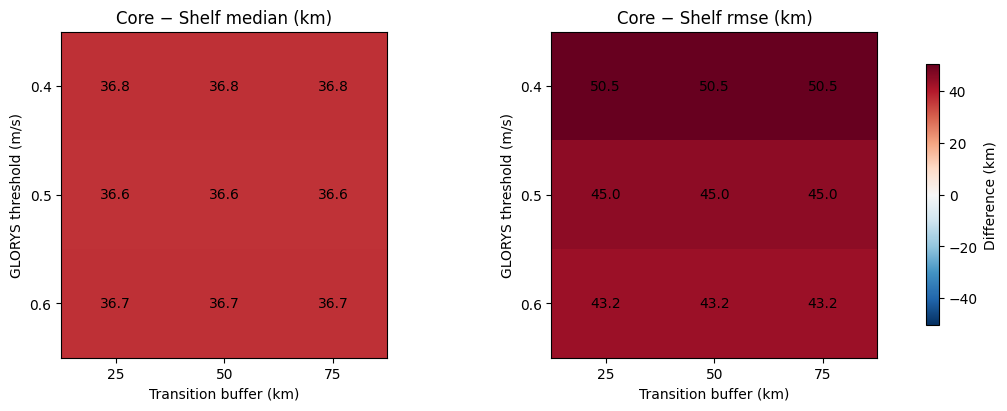

In [5]:
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for ax,metric in zip(axes,['median','rmse']):
    d=sensitivity.loc[sensitivity.metric.eq(metric)]
    grid=d.pivot(index='threshold_m_s',columns='buffer_km',values='core_minus_shelf_km').reindex(index=SPEED_THRESHOLDS,columns=BUFFERS_KM)
    im=ax.imshow(grid.to_numpy(),cmap='RdBu_r',vmin=-max(abs(sensitivity.core_minus_shelf_km)),vmax=max(abs(sensitivity.core_minus_shelf_km)))
    ax.set_xticks(range(3),BUFFERS_KM);ax.set_yticks(range(3),SPEED_THRESHOLDS)
    ax.set_xlabel('Transition buffer (km)');ax.set_ylabel('GLORYS threshold (m/s)');ax.set_title(f'Core − Shelf {metric} (km)')
    for i in range(3):
        for j in range(3): ax.text(j,i,f'{grid.iloc[i,j]:.1f}',ha='center',va='center',color='black')
fig.colorbar(im,ax=axes,label='Difference (km)',shrink=.8)
fig.savefig(FIG/'sensitivity_optimised_fnn.png',dpi=160)

from pathlib import Path

FIG = Path.home() / "Desktop" / "figure"
FIG.mkdir(parents=True, exist_ok=True)

fig.savefig(
    FIG / "sensitivity_analysis.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()



## 4. Cluster bootstrap — Optimised FNN, Core minus Shelf

This analysis uses the **fixed, observed 72h endpoint errors** of the global Optimised FNN. It joins test cases by `forecast_case_id`, checks the drifter IDs, and uses the original 0.5 m/s, 50 km regime labels. Each of 2,000 replicates samples all 71 test drifters with replacement and carries **every case from each selected drifter**. A drifter selected twice contributes its complete case block twice. The FNN is not retrained. For each replicate, Core and Shelf RMSE and median error are recomputed from the selected cases. The percentile 95% CI is for Core minus Shelf, in km. Some drifters can contribute cases to both regimes; their block is sampled once for both.


In [6]:
# Use the already validated test-case join from section 1; check the main labels again.
bootstrap_cases = cases[['forecast_case_id', 'ID', 'drifter_id', 'regime', 'error_72h_km']].copy()
assert bootstrap_cases.forecast_case_id.is_unique
assert (bootstrap_cases.ID.astype(str) == bootstrap_cases.drifter_id.astype(str)).all()
main_labels = labels.loc[np.isclose(labels.speed_threshold_m_s, 0.5) & labels.buffer_km.eq(50),
                         ['forecast_case_id', 'ID', 'regime']]
bootstrap_cases = bootstrap_cases.merge(main_labels, on='forecast_case_id',
                                        validate='one_to_one', suffixes=('', '_main'))
assert (bootstrap_cases.ID.astype(str) == bootstrap_cases.ID_main.astype(str)).all()
assert bootstrap_cases.regime.eq(bootstrap_cases.regime_main).all()
assert len(bootstrap_cases) == len(opt) == 757
assert bootstrap_cases.ID.nunique() == 71

errors = bootstrap_cases.error_72h_km.to_numpy(dtype=float)
regimes = bootstrap_cases.regime.to_numpy()
drifters = bootstrap_cases.ID.to_numpy()
assert np.isfinite(errors).all() and (errors >= 0).all()
cluster_ids = np.unique(drifters)
cluster_rows = [np.flatnonzero(drifters == cluster_id) for cluster_id in cluster_ids]
assert all(len(row) and np.all(drifters[row] == cluster_id)
           for cluster_id, row in zip(cluster_ids, cluster_rows))
row_cluster_index = np.empty(len(bootstrap_cases), dtype=int)
for j, rows_for_drifter in enumerate(cluster_rows):
    row_cluster_index[rows_for_drifter] = j

def endpoint_rmse(x):
    return float(np.sqrt(np.mean(np.square(x))))

def regime_metrics(row_indices):
    selected_errors = errors[row_indices]
    selected_regimes = regimes[row_indices]
    core_errors = selected_errors[selected_regimes == 'Kuroshio Core']
    shelf_errors = selected_errors[selected_regimes == 'Shelf']
    if not len(core_errors) or not len(shelf_errors):
        raise ValueError('A bootstrap draw has no Core or Shelf cases.')
    return (endpoint_rmse(core_errors), endpoint_rmse(shelf_errors),
            float(np.median(core_errors)), float(np.median(shelf_errors)))

observed = regime_metrics(np.arange(len(bootstrap_cases)))
rng = np.random.default_rng(SEED)
cluster_draws = rng.integers(0, len(cluster_ids), size=(N_BOOT, len(cluster_ids)))
replicates = np.empty((N_BOOT, 4), dtype=float)
for iteration, draw in enumerate(cluster_draws):
    sampled_rows = np.concatenate([cluster_rows[j] for j in draw])
    # A repeated drifter contributes its entire case block for each selection.
    actual_counts = np.bincount(sampled_rows, minlength=len(bootstrap_cases))
    multiplicity = np.bincount(draw, minlength=len(cluster_ids))
    assert np.array_equal(actual_counts, multiplicity[row_cluster_index])
    replicates[iteration] = regime_metrics(sampled_rows)

bootstrap_replicates = pd.DataFrame(replicates, columns=[
    'core_rmse_km', 'shelf_rmse_km', 'core_median_km', 'shelf_median_km'])
bootstrap_replicates.insert(0, 'iteration', np.arange(1, N_BOOT + 1))
bootstrap_replicates['rmse_core_minus_shelf_km'] = (bootstrap_replicates.core_rmse_km
                                                   - bootstrap_replicates.shelf_rmse_km)
bootstrap_replicates['median_core_minus_shelf_km'] = (bootstrap_replicates.core_median_km
                                                     - bootstrap_replicates.shelf_median_km)

summary_rows = []
for metric, core, shelf, column in [
    ('RMSE', observed[0], observed[1], 'rmse_core_minus_shelf_km'),
    ('Median error', observed[2], observed[3], 'median_core_minus_shelf_km')]:
    ci_low, ci_high = np.percentile(bootstrap_replicates[column], [2.5, 97.5])
    summary_rows.append({'metric': metric, 'core_km': core, 'shelf_km': shelf,
                         'core_minus_shelf_km': core - shelf,
                         'ci_low_km': ci_low, 'ci_high_km': ci_high,
                         'n_core_cases': int((regimes == 'Kuroshio Core').sum()),
                         'n_shelf_cases': int((regimes == 'Shelf').sum()),
                         'n_drifters': len(cluster_ids), 'n_bootstrap': N_BOOT})
bootstrap_summary = pd.DataFrame(summary_rows)
assert len(bootstrap_replicates) == N_BOOT and np.isfinite(replicates).all()
bootstrap_summary.to_csv(OUT / 'optimised_fnn_cluster_bootstrap_summary.csv', index=False)
bootstrap_replicates.to_csv(OUT / 'optimised_fnn_cluster_bootstrap_replicates.csv', index=False)
display(bootstrap_summary.round(2))
for row in bootstrap_summary.itertuples():
    conclusion = ('Core error is higher (95% CI excludes zero)'
                  if row.ci_low_km > 0 else
                  'Shelf error is higher (95% CI excludes zero)'
                  if row.ci_high_km < 0 else
                  '95% CI includes zero; difference is inconclusive')
    print(f'{row.metric}: {conclusion}.')


,metric,core_km,shelf_km,core_minus_shelf_km,ci_low_km,ci_high_km,n_core_cases,n_shelf_cases,n_drifters,n_bootstrap
0,RMSE,85.86,40.83,45.04,31.98,57.33,139,112,71,2000
1,Median error,61.22,24.66,36.55,27.57,52.30,139,112,71,2000


RMSE: Core error is higher (95% CI excludes zero).
Median error: Core error is higher (95% CI excludes zero).


Saved: /Users/zudemac/Desktop/figure/optimised_fnn_cluster_bootstrap_core_shelf.png
Saved: /Users/zudemac/Desktop/figure/optimised_fnn_cluster_bootstrap_core_shelf.svg


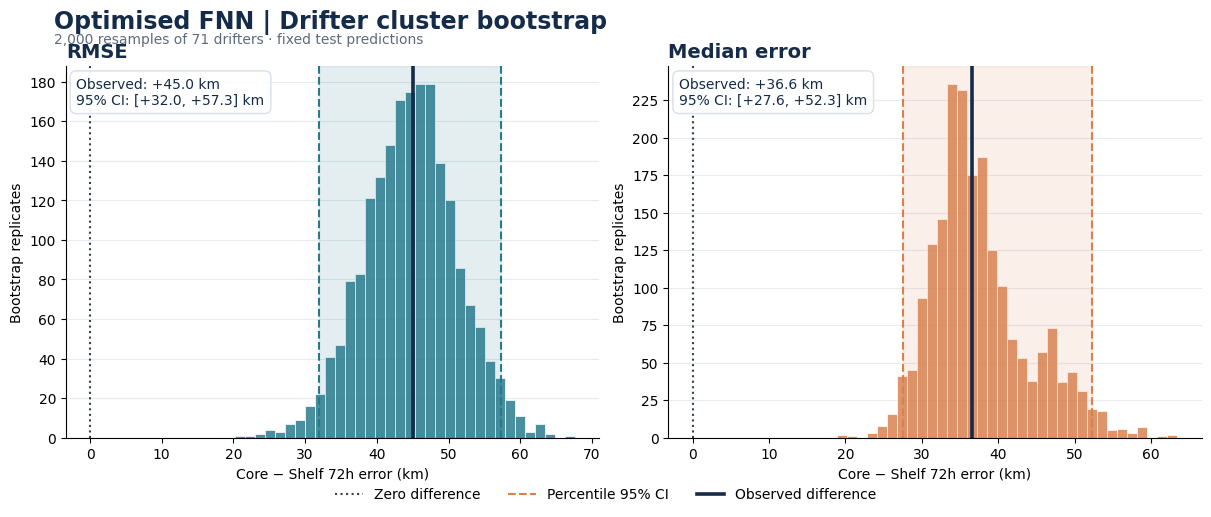

In [7]:
# Distribution and percentile intervals, with the observed Core minus Shelf difference.
import matplotlib.ticker as mticker

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout='constrained', facecolor='white')
plot_specs = [
    ('RMSE', 'rmse_core_minus_shelf_km', '#267A8C'),
    ('Median error', 'median_core_minus_shelf_km', '#D8814F'),
]
for ax, (metric, column, color) in zip(axes, plot_specs):
    row = bootstrap_summary.loc[bootstrap_summary.metric.eq(metric)].iloc[0]
    values = bootstrap_replicates[column].to_numpy()
    ax.hist(values, bins=34, color=color, alpha=0.84, edgecolor='white', linewidth=0.6)
    ax.axvline(0, color='#344054', linewidth=1.5, linestyle=':', label='Zero difference')
    ax.axvspan(row.ci_low_km, row.ci_high_km, color=color, alpha=0.12)
    ax.axvline(row.ci_low_km, color=color, linewidth=1.5, linestyle='--')
    ax.axvline(row.ci_high_km, color=color, linewidth=1.5, linestyle='--',
               label='Percentile 95% CI')
    ax.axvline(row.core_minus_shelf_km, color='#142B49', linewidth=2.6,
               label='Observed difference')
    ax.set_title(metric, loc='left', fontsize=14, fontweight='bold', color='#142B49')
    ax.set_xlabel('Core − Shelf 72h error (km)', fontsize=10)
    ax.set_ylabel('Bootstrap replicates', fontsize=10)
    ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    ax.grid(axis='y', color='#E6EBF0', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    ax.text(0.02, 0.97,
            f'Observed: {row.core_minus_shelf_km:+.1f} km\n'
            f'95% CI: [{row.ci_low_km:+.1f}, {row.ci_high_km:+.1f}] km',
            transform=ax.transAxes, va='top', ha='left', fontsize=10,
            color='#142B49', bbox={'boxstyle': 'round,pad=0.45',
                                    'facecolor': 'white', 'edgecolor': '#D6DEE8',
                                    'alpha': 0.95})
handles, labels_legend = axes[1].get_legend_handles_labels()
fig.legend(handles, labels_legend, loc='lower center', bbox_to_anchor=(0.5, -0.06),
           ncol=3, frameon=False, fontsize=10)
fig.suptitle('Optimised FNN | Drifter cluster bootstrap', x=0.04, ha='left',
             fontsize=17, fontweight='bold', color='#142B49')
fig.text(0.04, 0.92, f'{N_BOOT:,} resamples of {len(cluster_ids)} drifters · fixed test predictions',
         fontsize=10, color='#5F6B7A')
png_path = FIG / 'optimised_fnn_cluster_bootstrap_core_shelf.png'
svg_path = FIG / 'optimised_fnn_cluster_bootstrap_core_shelf.svg'
fig.savefig(png_path, dpi=300, facecolor='white', bbox_inches='tight')
fig.savefig(svg_path, facecolor='white', bbox_inches='tight')
print('Saved:', png_path)
print('Saved:', svg_path)
plt.show()


## 5. Regional retraining

Both strategies are scored on the same 139 held-out Kuroshio Core forecast origins at the main regime setting (0.5 m/s and 50 km). Global scores are recomputed from each model’s saved RQ1 test-case errors. Regional fits use the 646 Core training origins. All fitting, including standardisation, excludes calibration and test drifters.

| Display | Model version and Core-only fit |
| --- | --- |
| KNN | Optimised Weighted KNN (RQ1 notebook 12), direct displacement, spatial boost, no PCA, 24 neighbours, power 3 |
| FNN | Optimised FNN (RQ1 notebook 11), direct 128–64 network, L2 0.001, learning rate 0.001, batch 256, 129 epochs, seeds 2026/2037/2048 averaged in displacement space |
| Random Forest | Original Random Forest (RQ1 notebook 08), 400 bootstrap trees, depth 24, leaf size 1, all features, seed 2026 |
| Ridge | Original multi-output Ridge (RQ1 notebook 03), fixed RQ1 penalty α = 100 |
| VAR | Pooled VAR(1) (RQ1 notebook 05), fitted to unique one-hour velocity transitions within the 24-hour histories of Core training cases, following the regional protocol in `RQ2/19_kuroshio_all_models.py` |

Fixed RQ1 settings let the supervised models be compared with their global counterparts using the same configurations. VAR uses a pooled least-squares fit with an intercept and integrates recursive hourly predictions from the origin velocity.

A missing input or mismatched case join is reported with its source. Affected values stay blank and percentage reductions require a valid pair.

In [8]:
HISTORY_HOURS,HORIZON_HOURS=24,72
EARTH_RADIUS_KM=6371.0
BEST_CONFIG={'name':'128-64 direct L2','hidden_sizes':(128,64),'l2':1e-3,'learning_rate':1e-3,'batch_size':256,'target_mode':'direct'}
SELECTED_EPOCHS=129
FINAL_SEEDS=[2026,2037,2048]
# Displacement geometry and the Optimised FNN final fit from the original notebook.
def latlon_to_local_km(origin_lat, origin_lon, latitude, longitude):
    lat0, lon0 = np.deg2rad(origin_lat), np.deg2rad(origin_lon)
    lat1, lon1 = np.deg2rad(latitude), np.deg2rad(longitude)
    dlon = (lon1 - lon0 + np.pi) % (2*np.pi) - np.pi
    dlat = lat1 - lat0
    a = np.sin(dlat/2)**2 + np.cos(lat0)*np.cos(lat1)*np.sin(dlon/2)**2
    angle = 2*np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    bearing = np.arctan2(np.sin(dlon)*np.cos(lat1),
                         np.cos(lat0)*np.sin(lat1)-np.sin(lat0)*np.cos(lat1)*np.cos(dlon))
    distance = EARTH_RADIUS_KM * angle
    return distance*np.sin(bearing), distance*np.cos(bearing)

def local_km_to_latlon(origin_lat, origin_lon, east_km, north_km):
    lat0, lon0 = np.deg2rad(origin_lat), np.deg2rad(origin_lon)
    distance = np.hypot(east_km, north_km)
    bearing = np.arctan2(east_km, north_km)
    angular = distance / EARTH_RADIUS_KM
    lat = np.arcsin(np.sin(lat0)*np.cos(angular)+np.cos(lat0)*np.sin(angular)*np.cos(bearing))
    lon = lon0 + np.arctan2(np.sin(bearing)*np.sin(angular)*np.cos(lat0),
                            np.cos(angular)-np.sin(lat0)*np.sin(lat))
    return np.rad2deg(lat), (np.rad2deg(lon)+180)%360-180

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.deg2rad, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 2*EARTH_RADIUS_KM*np.arcsin(np.sqrt(np.clip(a, 0, 1)))

def initialise(layer_sizes, rng):
    return [{'W':rng.normal(0,np.sqrt(2/fan_in),(fan_in,fan_out)), 'b':np.zeros(fan_out)}
            for fan_in,fan_out in zip(layer_sizes[:-1],layer_sizes[1:])]

def forward(parameters, Xb):
    acts, zs, cur = [Xb], [], Xb
    for j, layer in enumerate(parameters):
        z = cur@layer['W'] + layer['b']; zs.append(z)
        cur = np.maximum(z,0) if j < len(parameters)-1 else z
        acts.append(cur)
    return cur, acts, zs

def loss_and_grads(parameters, Xb, Yb, l2):
    pred, acts, zs = forward(parameters,Xb)
    residual = pred-Yb
    # Keep the original objective: standardised MSE + lambda * sum(W^2)
    loss = np.mean(residual**2) + l2*sum(np.sum(p['W']**2) for p in parameters)
    delta = 2*residual/residual.size
    grads = [None]*len(parameters)
    for j in range(len(parameters)-1,-1,-1):
        grads[j] = {'W':acts[j].T@delta + 2*l2*parameters[j]['W'], 'b':delta.sum(0)}
        if j>0: delta = (delta@parameters[j]['W'].T)*(zs[j-1]>0)
    return loss, grads

def endpoint_errors(pred_abs, true_abs, origin_rows):
    p = pred_abs.reshape(-1,72,2)[:,-1,:]
    y = true_abs.reshape(-1,72,2)[:,-1,:]
    olat = origin_rows.origin_latitude.to_numpy(); olon = origin_rows.origin_longitude.to_numpy()
    plat,plon = local_km_to_latlon(olat,olon,p[:,0],p[:,1])
    tlat,tlon = local_km_to_latlon(olat,olon,y[:,0],y[:,1])
    return haversine_km(plat,plon,tlat,tlon)

def predict_model(model,Xnew):
    z=(Xnew-model['x_mean'])/model['x_scale']
    return forward(model['parameters'],z)[0]*model['y_scale']+model['y_mean']

def fit_final(Xraw,Ymodel,config,epochs,seed):
    xm,xs=Xraw.mean(0),Xraw.std(0); xs[xs<1e-12]=1
    ym,ys=Ymodel.mean(0),Ymodel.std(0); ys[ys<1e-12]=1
    Xtr=(Xraw-xm)/xs; Ytr=(Ymodel-ym)/ys; rng=np.random.default_rng(seed)
    params=initialise((98,*config['hidden_sizes'],144),rng)
    m=[{'W':np.zeros_like(p['W']),'b':np.zeros_like(p['b'])} for p in params]; v=copy.deepcopy(m); step=0
    for epoch in range(epochs):
        perm=rng.permutation(len(Xtr))
        for start in range(0,len(Xtr),config['batch_size']):
            batch=perm[start:start+config['batch_size']]
            _,grads=loss_and_grads(params,Xtr[batch],Ytr[batch],config['l2']); step+=1
            for j,(p,g) in enumerate(zip(params,grads)):
                for key in ('W','b'):
                    m[j][key]=.9*m[j][key]+.1*g[key]; v[j][key]=.999*v[j][key]+.001*g[key]**2
                    p[key]-=config['learning_rate']*(m[j][key]/(1-.9**step))/(np.sqrt(v[j][key]/(1-.999**step))+1e-8)
    return dict(parameters=params,x_mean=xm,x_scale=xs,y_mean=ym,y_scale=ys)

def fit_ridge(X_train, Y_train, alpha):
    x_mean = X_train.mean(axis=0)
    x_scale = X_train.std(axis=0)
    x_scale[x_scale < 1e-12] = 1.0
    y_mean = Y_train.mean(axis=0)

    X_standard = (X_train - x_mean) / x_scale
    gram = X_standard.T @ X_standard
    coefficients = np.linalg.solve(
        gram + alpha * np.eye(gram.shape[0]),
        X_standard.T @ (Y_train - y_mean),
    )
    return {
        'alpha': float(alpha),
        'x_mean': x_mean,
        'x_scale': x_scale,
        'y_mean': y_mean,
        'coefficients': coefficients,
    }

def predict_ridge(model, X_new):
    X_standard = (X_new - model['x_mean']) / model['x_scale']
    return X_standard @ model['coefficients'] + model['y_mean']

In [9]:
def load_regional_training_data():
    origins=pd.read_parquet(ORIGINS).sort_values('forecast_case_id').reset_index(drop=True)
    observations=pd.read_parquet(OBS,columns=['ID','segment_id','segment_step','time','latitude','longitude','ve','vn'])
    n_cases=len(origins)
    history=origins[['forecast_case_id','ID','segment_id','history_start_step','origin_latitude','origin_longitude']].loc[origins.index.repeat(HISTORY_HOURS)].reset_index(drop=True)
    history['history_index']=np.tile(np.arange(HISTORY_HOURS),n_cases)
    history['segment_step']=history.history_start_step+history.history_index
    history=history.merge(observations,on=['ID','segment_id','segment_step'],how='left',validate='many_to_one').sort_values(['forecast_case_id','history_index']).reset_index(drop=True)
    history['relative_east_km'],history['relative_north_km']=latlon_to_local_km(history.origin_latitude,history.origin_longitude,history.latitude,history.longitude)
    hv=history[['relative_east_km','relative_north_km','ve','vn']].to_numpy().reshape(n_cases,24,4)
    X=np.column_stack([origins.origin_latitude,origins.origin_longitude,hv.reshape(n_cases,-1)]).astype(float)
    targets=origins[['forecast_case_id','ID','segment_id','target_start_step','origin_latitude','origin_longitude']].loc[origins.index.repeat(HORIZON_HOURS)].reset_index(drop=True)
    targets['lead_time_hours']=np.tile(np.arange(1,73),n_cases)
    targets['segment_step']=targets.target_start_step+targets.lead_time_hours-1
    targets=targets.merge(observations[['ID','segment_id','segment_step','latitude','longitude']],on=['ID','segment_id','segment_step'],how='left',validate='many_to_one').sort_values(['forecast_case_id','lead_time_hours']).reset_index(drop=True)
    targets['target_east_km'],targets['target_north_km']=latlon_to_local_km(targets.origin_latitude,targets.origin_longitude,targets.latitude,targets.longitude)
    Y=targets[['target_east_km','target_north_km']].to_numpy().reshape(n_cases,144).astype(float)
    if X.shape != (5117, 98) or Y.shape != (5117, 144):
        raise ValueError("Unexpected trajectory array dimensions.")
    if not np.isfinite(X).all() or not np.isfinite(Y).all():
        raise ValueError("Incomplete trajectory history or targets.")

    expected = reg.set_index('forecast_case_id')[['ID', 'partition', 'regime']]
    if set(origins.forecast_case_id) != set(expected.index) or not origins.forecast_case_id.is_unique:
        raise ValueError("Origins do not match the unique regime case IDs.")
    aligned = expected.loc[origins.forecast_case_id]
    if not np.array_equal(aligned.ID.to_numpy(), origins.ID.to_numpy()):
        raise ValueError("Drifter IDs differ between origins and regime labels.")
    if not np.array_equal(aligned.partition.to_numpy(), origins.partition.to_numpy()):
        raise ValueError("Partitions differ between origins and regime labels.")
    is_core = aligned.regime.eq('Kuroshio Core').to_numpy()
    train = np.flatnonzero(origins.partition.eq('training') & is_core)
    test = np.flatnonzero(origins.partition.eq('test') & is_core)
    if len(train) != 646 or set(origins.loc[test, 'forecast_case_id']) != set(core_cases.index):
        raise ValueError("Unexpected Core training or test coverage.")
    if set(origins.loc[train, 'ID']) & set(origins.loc[test, 'ID']):
        raise ValueError("Training and test drifters overlap.")
    return origins, history, X, Y, train, test

core_cases = reg.loc[
    reg.partition.eq('test') & reg.regime.eq('Kuroshio Core'), ['forecast_case_id', 'ID']
].set_index('forecast_case_id', verify_integrity=True).sort_index()
assert len(core_cases) == 139 and core_cases.ID.nunique() == 45
print(f"Core test set: {len(core_cases)} cases from {core_cases.ID.nunique()} drifters.")

regional_input_issue = None
missing_parquet = [str(p) for p in (ORIGINS, OBS) if not p.is_file()]
if missing_parquet:
    regional_input_issue = "Missing trajectory inputs: " + ", ".join(missing_parquet)
else:
    try:
        origins, history, X, Y, core_train, core_test = load_regional_training_data()
    except (OSError, ValueError, KeyError, ImportError) as exc:
        regional_input_issue = f"Could not prepare regional data ({ORIGINS}, {OBS}): {exc}"
if regional_input_issue:
    print(regional_input_issue)
else:
    print(f"Core training set: {len(core_train)} cases from {origins.loc[core_train, 'ID'].nunique()} drifters.")

Core test set: 139 cases from 45 drifters.
Core training set: 646 cases from 208 drifters.


In [10]:
# Optimised KNN uses the RQ1 spatial-boost representation and inverse-distance weights.
def refit_knn(x_train, y_train, x_test):
    mean, scale = x_train.mean(axis=0), x_train.std(axis=0)
    scale[scale < 1e-12] = 1.0
    scale[:2] /= np.sqrt(8.0)
    a, b = (x_train - mean) / scale, (x_test - mean) / scale
    distance_sq = (np.square(b).sum(1)[:, None] + np.square(a).sum(1) - 2 * b @ a.T) / a.shape[1]
    distance = np.sqrt(np.maximum(distance_sq, 0))
    k = 24
    nearest = np.argpartition(distance, k - 1, axis=1)[:, :k]
    weights = (np.take_along_axis(distance, nearest, axis=1) + 1e-8) ** -3
    weights /= weights.sum(axis=1, keepdims=True)
    return np.einsum("nk,nko->no", weights, y_train[nearest], optimize=True)


def refit_fnn(x_train, y_train, x_test):
    predictions = []
    for seed in FINAL_SEEDS:
        model = fit_final(x_train, y_train, BEST_CONFIG, SELECTED_EPOCHS, seed)
        predictions.append(predict_model(model, x_test))
    return np.mean(predictions, axis=0)


def refit_original_forest(x_train, y_train, x_test):
    from sklearn.ensemble import RandomForestRegressor

    forest = RandomForestRegressor(
        n_estimators=400, max_depth=24, min_samples_leaf=1, max_features=1.0,
        bootstrap=True, random_state=2026, n_jobs=-1,
    )
    return forest.fit(x_train, y_train).predict(x_test)


def refit_ridge(x_train, y_train, x_test):
    return predict_ridge(fit_ridge(x_train, y_train, alpha=100.0), x_test)


def refit_var():
    keys = ['ID', 'segment_id', 'segment_step']
    velocity_cols = ['ve', 'vn']
    windows = history.loc[history.forecast_case_id.isin(origins.loc[core_train, 'forecast_case_id'])].copy()
    windows[['next_ve', 'next_vn']] = windows.groupby('forecast_case_id')[velocity_cols].shift(-1)
    transitions = windows.loc[windows.history_index.lt(HISTORY_HOURS - 1)].drop_duplicates(keys)
    velocity = transitions[velocity_cols].to_numpy()
    design = np.column_stack([np.ones(len(velocity)), velocity])
    coef = np.linalg.lstsq(design, transitions[['next_ve', 'next_vn']].to_numpy(), rcond=None)[0]
    initial = origins.loc[core_test, ['origin_ve', 'origin_vn']].to_numpy()
    prediction = np.empty((len(initial), HORIZON_HOURS, 2))
    velocity = initial.copy()
    cumulative = np.zeros_like(velocity)
    for hour in range(HORIZON_HOURS):
        velocity = coef[0] + velocity @ coef[1:]
        cumulative += 3.6 * velocity
        prediction[:, hour] = cumulative
    return prediction.reshape(len(initial), -1)


def read_core_errors(path, error_column):
    frame = pd.read_csv(path).set_index('forecast_case_id', verify_integrity=True)
    expected_test = reg.loc[reg.partition.eq('test')].set_index('forecast_case_id')
    if set(frame.index) != set(expected_test.index):
        raise ValueError("Saved case IDs do not match the fixed test set.")
    frame = frame.loc[core_cases.index]
    for id_column in ('ID', 'drifter_id'):
        if id_column in frame and not np.array_equal(frame[id_column].to_numpy(), core_cases.ID.to_numpy()):
            raise ValueError(f"Saved {id_column} does not match Core test drifters.")
    return checked_errors(frame[error_column])


def checked_errors(values):
    values = np.asarray(values, dtype=float)
    if values.shape != (len(core_cases),) or not np.isfinite(values).all() or (values < 0).any():
        raise ValueError("Expected one finite nonnegative error per Core test case.")
    return values


model_specs = [
    ('KNN', 'Optimised Weighted KNN', 'optimised_knn', 'error_72h_km', refit_knn),
    ('FNN', 'Optimised FNN', 'optimised_fnn', 'error_72h_km', refit_fnn),
    ('Random Forest', 'Original Random Forest', 'random_forest', 'final_72h_error_km', refit_original_forest),
    ('Ridge', 'Multi-output Ridge', 'ridge', 'final_72h_error_km', refit_ridge),
    ('VAR', 'Pooled VAR(1)', 'var1', 'final_72h_error_km', None),
]
comparison_rows, case_tables = [], []
for name, version, slug, error_column, refit in model_specs:
    path = rq1_output(f'{slug}_test_case_metrics.csv')
    paired = core_cases.copy()
    issues = []
    try:
        paired['global_error_72h_km'] = read_core_errors(path, error_column)
    except (OSError, ValueError, KeyError) as exc:
        paired['global_error_72h_km'] = np.nan
        issues.append(f"Global unavailable ({path}): {exc}")

    paired['regional_error_72h_km'] = np.nan
    if regional_input_issue:
        issues.append(regional_input_issue)
    else:
        try:
            print(f"Fitting {name} on Core training data.")
            prediction = refit_var() if refit is None else refit(X[core_train], Y[core_train], X[core_test])
            errors = endpoint_errors(prediction, Y[core_test], origins.loc[core_test])
            regional_errors = pd.Series(errors, index=origins.loc[core_test, 'forecast_case_id'])
            paired['regional_error_72h_km'] = checked_errors(regional_errors.loc[core_cases.index])
        except (ImportError, OSError, ValueError, KeyError, np.linalg.LinAlgError) as exc:
            issues.append(f"Regional unavailable: {exc}")

    global_km = rmse(paired.global_error_72h_km.to_numpy())
    regional_km = rmse(paired.regional_error_72h_km.to_numpy())
    reduction = 100 * (global_km - regional_km) / global_km if global_km > 0 else np.nan
    if global_km == 0:
        issues.append("Percentage reduction is undefined for zero global RMSE.")
    comparison_rows.append({
        'model': name, 'version': version,
        'global_rmse_km': global_km, 'regional_rmse_km': regional_km,
        'reduction_pct': reduction,
        'n_core_cases': len(paired), 'n_core_drifters': paired.ID.nunique(),
        'global_source': str(path), 'status': " | ".join(issues) or 'Complete',
    })
    if issues:
        print(f"{name}: {' | '.join(issues)}")
    case_tables.append(paired.assign(model=name).reset_index())

regional_comparison = pd.DataFrame(comparison_rows).set_index('model')
regional_case_errors = pd.concat(case_tables, ignore_index=True)
regional_comparison.to_csv(OUT / 'regional_retraining_five_models_summary.csv')
regional_case_errors.to_csv(OUT / 'regional_retraining_five_models_case_errors.csv', index=False)
display(regional_comparison[['global_rmse_km', 'regional_rmse_km', 'reduction_pct']].round(2))

Fitting KNN on Core training data.
Fitting FNN on Core training data.
Fitting Random Forest on Core training data.
Fitting Ridge on Core training data.
Fitting VAR on Core training data.


,global_rmse_km,regional_rmse_km,reduction_pct
model,,,
KNN,89.57,88.45,1.25
FNN,85.86,82.12,4.35
Random Forest,86.53,83.36,3.66
Ridge,92.08,86.51,6.04
VAR,111.47,94.34,15.37


## 6. Regional RMSE and paired FNN uncertainty

RMSE is the square root of the mean squared 72-hour great-circle endpoint error over the Core test cases. Reduction is 100 × (global RMSE − regional RMSE) / global RMSE, so a negative percentage indicates higher error after retraining.

The paired FNN bootstrap resamples the 45 Core test drifters with replacement and retains all paired cases from each selected drifter. The 95% percentile intervals describe the global minus regional difference, in km, for median and RMSE.

In [11]:
result = regional_case_errors.loc[regional_case_errors.model.eq('FNN')]
if result[['global_error_72h_km', 'regional_error_72h_km']].notna().all().all():
    result.drop(columns='model').to_csv(OUT / 'core_test_global_vs_regional_optimised_fnn.csv', index=False)
    g=result.global_error_72h_km.to_numpy(float); r=result.regional_error_72h_km.to_numpy(float)
    groups=result.ID.to_numpy(); uniq=np.unique(groups); idx=[np.flatnonzero(groups==x) for x in uniq]
    rng=np.random.default_rng(SEED)
    draws=rng.integers(0,len(uniq),size=(N_BOOT,len(uniq)))
    comparison=[]
    for metric,func in [('median',np.median),('rmse',rmse)]:
        reps=[float(func(g[bi])-func(r[bi])) for draw in draws for bi in [np.concatenate([idx[j] for j in draw])]]
        lo,hi=np.percentile(reps,[2.5,97.5])
        comparison.append({'metric':metric,'global_km':float(func(g)),'regional_km':float(func(r)),'global_minus_regional_km':float(func(g)-func(r)),'ci_low_km':lo,'ci_high_km':hi,'n_cases':len(result),'n_drifters':len(uniq),'valid_bootstrap':len(reps)})
    comparison=pd.DataFrame(comparison)
    comparison.to_csv(OUT/'core_retraining_comparison.csv',index=False)
    display(comparison.round(2))
else:
    print("Paired FNN bootstrap unavailable because one or both error series are missing.")

,metric,global_km,regional_km,global_minus_regional_km,ci_low_km,ci_high_km,n_cases,n_drifters,valid_bootstrap
0,median,61.22,62.17,-0.95,-6.44,10.49,139,45,2000
1,rmse,85.86,82.12,3.74,0.60,6.85,139,45,2000


### Regional retraining figures

Both figures are exported as 300 dpi PNG and editable SVG to `~/Desktop/figure`.

Saved /Users/zudemac/Desktop/figure/regional_retraining_rmse_reduction.png
Saved /Users/zudemac/Desktop/figure/regional_retraining_rmse_reduction.svg


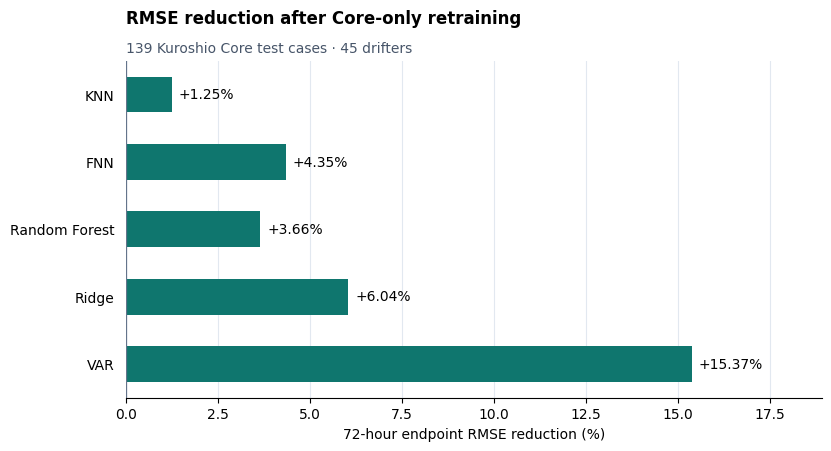

Saved /Users/zudemac/Desktop/figure/regional_retraining_rmse_comparison.png
Saved /Users/zudemac/Desktop/figure/regional_retraining_rmse_comparison.svg


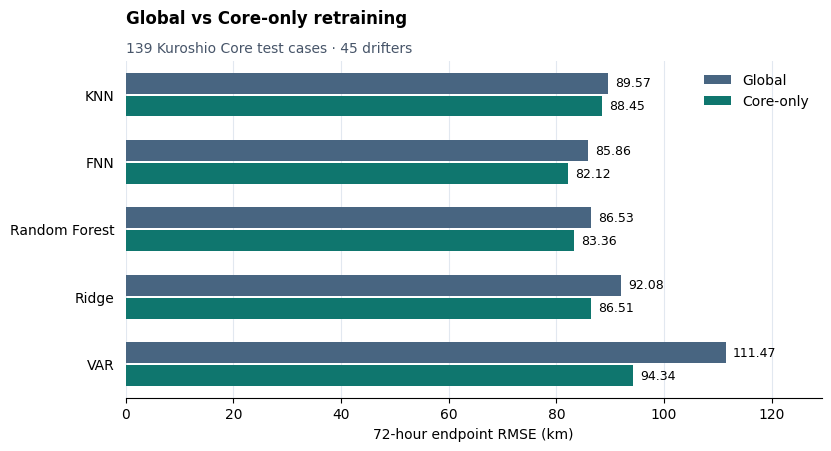

In [12]:
models = regional_comparison.index
positions = np.arange(len(models))
caption = f"{len(core_cases)} Kuroshio Core test cases · {core_cases.ID.nunique()} drifters"
plt.rcParams['svg.fonttype'] = 'none'

def regional_axes(title, xlabel):
    fig, ax = plt.subplots(figsize=(8.2, 4.4), layout='constrained')
    ax.set_title(title, loc='left', fontweight='bold', pad=27)
    ax.text(0, 1.025, caption, transform=ax.transAxes, color='#475569', fontsize=10)
    ax.set_yticks(positions, models)
    ax.invert_yaxis()
    ax.set_xlabel(xlabel)
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.tick_params(axis='y', length=0, pad=8)
    ax.set_axisbelow(True)
    ax.grid(axis='x', color='#e2e8f0')
    return fig, ax


def save_regional_figure(fig, stem):
    for extension in ('png', 'svg'):
        target = FIG / f'{stem}.{extension}'
        fig.savefig(target, dpi=300, facecolor='white')
        print(f"Saved {target}")
    plt.show()


fig, ax = regional_axes('RMSE reduction after Core-only retraining', '72-hour endpoint RMSE reduction (%)')
reduction = regional_comparison.reduction_pct.to_numpy()
valid = np.isfinite(reduction)
colors = np.where(reduction[valid] >= 0, '#0f766e', '#b45309')
bars = ax.barh(positions[valid], reduction[valid], color=colors, height=0.53)
ax.bar_label(bars, labels=[f'{value:+.2f}%' for value in reduction[valid]], padding=5)
ax.axvline(0, color='#64748b', linewidth=0.9)
for position in positions[~valid]:
    ax.annotate('Unavailable', (0, position), xytext=(6, 0),
                textcoords='offset points', va='center', color='#64748b')
ax.margins(x=0.23, y=0.10)
ax.set_ylim(len(models) - 0.5, -0.5)
save_regional_figure(fig, 'regional_retraining_rmse_reduction')

fig, ax = regional_axes('Global vs Core-only retraining', '72-hour endpoint RMSE (km)')
for column, label, color, shift in [
    ('global_rmse_km', 'Global', '#486581', -0.17),
    ('regional_rmse_km', 'Core-only', '#0f766e', 0.17),
]:
    values = regional_comparison[column].to_numpy()
    valid = np.isfinite(values)
    bars = ax.barh(positions[valid] + shift, values[valid], height=0.31, label=label, color=color)
    ax.bar_label(bars, labels=[f'{value:.2f}' for value in values[valid]], padding=5, fontsize=9)
    for position in positions[~valid]:
        ax.annotate('Unavailable', (0, position + shift), xytext=(6, 0),
                    textcoords='offset points', va='center', color='#64748b', fontsize=9)
ax.set_ylim(len(models) - 0.5, -0.5)
ax.margins(x=0.16)
ax.set_xlim(left=0)
ax.legend(loc='upper right', frameon=False)
save_regional_figure(fig, 'regional_retraining_rmse_comparison')

## Reading the results

- Sensitivity table: Core−Shelf is a **difference of two group summaries**, not an individual travel distance or buffer distance. A positive number means the optimised global FNN has larger Core error. RMSE gives greater weight to large errors.
- Regional table: Global−Regional >0 means Core-only retraining improved the metric on identical Core cases. If a percentile CI spans zero, the observed direction is uncertain under drifter resampling.
- These are endpoint errors at 72h. The 25/50/75 **km** values define the spatial Transition buffer around the Core, not forecast errors.

- Cluster bootstrap: the 95% percentile intervals quantify uncertainty when whole test drifters are resampled. A CI excluding zero supports a directional Core−Shelf difference for that metric; a CI containing zero does not.
